# Part A: Fraud Detection: Analysis

**Section 1: short, purposeful EDA.** Each check below exists because it changes a modelling or evaluation decision; the decision is stated after each one.

Data: ULB credit card transactions (Sept 2013, European cardholders, 2 days). `V1`–`V28` are PCA components of undisclosed original features; only `Time` and `Amount` are raw.

In [1]:
import sys
from pathlib import Path

# Make the repo root importable no matter where Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from part_a_fraud.src.data import CSV_PATH, TARGET, FEATURES, verify, load, time_split

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
raw = verify(pd.read_csv(CSV_PATH))   # all rows, incl. duplicates
df = load()                           # deduplicated, sorted by Time
train, val, test = time_split(df)
print(f"raw: {raw.shape}, deduplicated: {df.shape}")

raw: (284807, 31), deduplicated: (283726, 31)


## 1. Class imbalance and the accuracy trap

In [2]:
counts = raw[TARGET].value_counts().rename({0: "legit", 1: "fraud"})
print(counts.to_string())
print(f"\nFraud rate: {raw[TARGET].mean():.3%}  (1 fraud per {1/raw[TARGET].mean():,.0f} transactions)")
print(f"Accuracy of a model that ALWAYS predicts 'legit': {1 - raw[TARGET].mean():.2%}  -- and it catches zero fraud")

Class
legit    284315
fraud       492

Fraud rate: 0.173%  (1 fraud per 579 transactions)
Accuracy of a model that ALWAYS predicts 'legit': 99.83%  -- and it catches zero fraud


**Decision:** accuracy is meaningless here. Primary metric is **PR-AUC (average precision)**, which focuses on the rare class; plus recall at a fixed precision / alert budget, and money caught vs. missed. An always-legit baseline goes in the results table to make this concrete.

## 2. Transaction amount: fraud vs. legit

          count    mean     std  min    50%     90%      99%       max
Class                                                                 
legit  284315.0   88.29  250.11  0.0  22.00  202.72  1016.97  25691.16
fraud     492.0  122.21  256.68  0.0   9.25  346.75  1357.43   2125.87


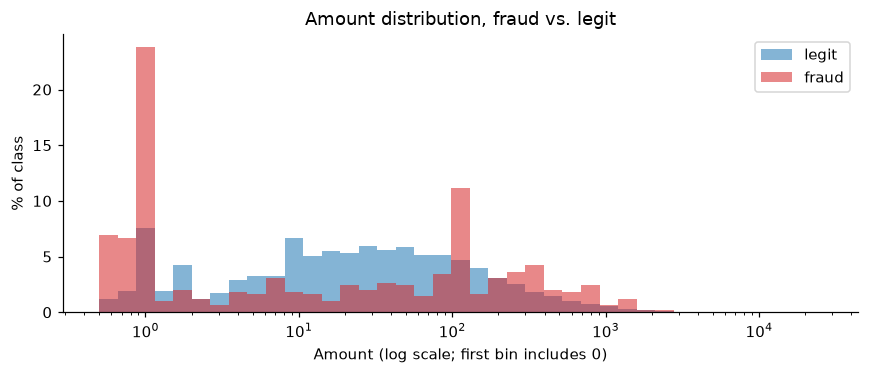

Total fraud amount: 60,128 | share from top 10% of fraud transactions: 61%
Fraud transactions with Amount == 0: 27


In [3]:
print(raw.groupby(TARGET)["Amount"].describe(percentiles=[.5, .9, .99]).rename(index={0: "legit", 1: "fraud"}).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
# log-spaced bins; y = share of that class's transactions in each bin (comparable across classes)
bins = np.logspace(np.log10(0.5), np.log10(raw["Amount"].max() + 1), 40)
for cls, label, color in [(0, "legit", "tab:blue"), (1, "fraud", "tab:red")]:
    a = raw.loc[raw[TARGET] == cls, "Amount"].clip(lower=0.5)   # amounts < 0.5 (incl. 0) go in the first bin
    ax.hist(a, bins=bins, weights=np.full(len(a), 100 / len(a)), alpha=.55, label=label, color=color)
ax.set_xscale("log"); ax.set_xlabel("Amount (log scale; first bin includes 0)"); ax.set_ylabel("% of class"); ax.legend()
ax.set_title("Amount distribution, fraud vs. legit")
plt.tight_layout(); plt.show()

fraud_amt = raw.loc[raw[TARGET] == 1, "Amount"]
print(f"Total fraud amount: {fraud_amt.sum():,.0f} | share from top 10% of fraud transactions: "
      f"{fraud_amt.nlargest(int(len(fraud_amt) * .1)).sum() / fraud_amt.sum():.0%}")
print(f"Fraud transactions with Amount == 0: {(fraud_amt == 0).sum()}")

**Decision:** fraud amounts are bimodal and heavy-tailed. The median fraud is only ~9 (vs. ~22 for legit), with many tiny or zero-amount transactions (typical card testing), while the top 10% of frauds carry ~61% of the fraud money. So counting frauds caught is not enough. The evaluation also reports **amount caught vs. missed**, and the false-negative cost uses the transaction amount. `Amount` is skewed, so it is log-transformed for Logistic Regression (tree models don't need it).

## 3. Fraud over time (2 days)

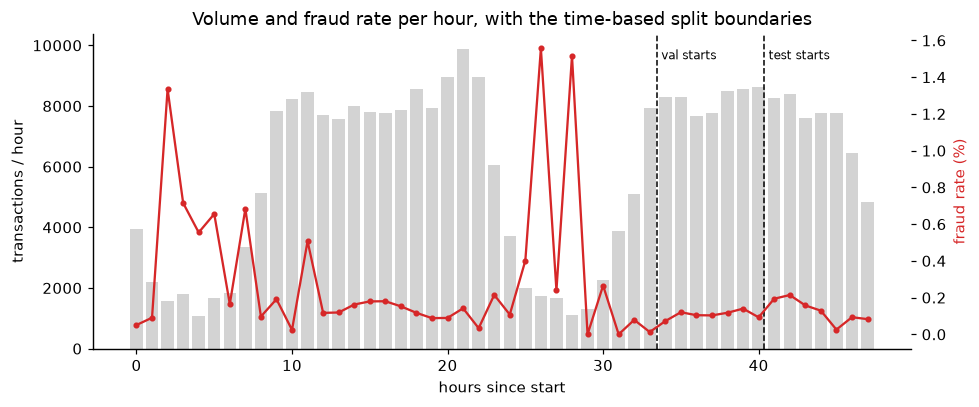

,rows,frauds,fraud rate %,fraud amount
train,170235.0,342.0,0.201,38633.0
val,56745.0,57.0,0.100,12231.0
test,56746.0,74.0,0.130,7728.0


In [4]:
hours = (df["Time"] // 3600).astype(int)
by_hour = df.groupby(hours)[TARGET].agg(["size", "sum"])
by_hour["rate"] = by_hour["sum"] / by_hour["size"]

fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.bar(by_hour.index, by_hour["size"], color="lightgray", label="transactions / hour")
ax1.set_xlabel("hours since start"); ax1.set_ylabel("transactions / hour")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["rate"] * 100, color="tab:red", marker=".", label="fraud rate %")
ax2.set_ylabel("fraud rate (%)", color="tab:red")
for t, name in [(val["Time"].min(), "val starts"), (test["Time"].min(), "test starts")]:
    ax1.axvline(t / 3600, color="k", ls="--", lw=1); ax1.text(t / 3600 + .3, ax1.get_ylim()[1] * .92, name, fontsize=8)
ax1.set_title("Volume and fraud rate per hour, with the time-based split boundaries")
plt.tight_layout(); plt.show()

split_summary = pd.DataFrame({name: {"rows": len(p), "frauds": int(p[TARGET].sum()), "fraud rate %": round(p[TARGET].mean() * 100, 3),
                                     "fraud amount": round(p.loc[p[TARGET] == 1, "Amount"].sum())}
                              for name, p in [("train", train), ("val", val), ("test", test)]}).T
split_summary

**Decision:**
- Volume follows a day/night cycle and the fraud *rate* spikes at night (up to ~1.5% per hour) when legit volume drops. Hour-of-day is a plausible production feature, but here validation and test contain no night hours, so it couldn't be validated. Raw `Time` (seconds since the file started) is **not** used as a model feature; see section 2.3 for the evidence.
- **Both nights fall in the training period**; validation and test are day-2 daytime/evening only. That is why the fraud rate is ~0.20% in train but ~0.10% in val and ~0.13% in test. The model is validated and tested on a *different regime* than most of its training fraud. This is a weakness of 2 days of data, not something a split can fix; a shuffled split would hide it and look better. Thresholds chosen on validation may not transfer perfectly to test; we report what actually happens.
- Only **57 frauds in validation and 74 in test** (test fraud totals just ~7.7k in money), so every metric gets a **bootstrap confidence interval**.

## 4. Exact duplicate rows

In [5]:
dup_mask = raw.duplicated(keep=False)
print(f"Rows involved in exact duplication: {dup_mask.sum():,} | extra copies dropped: {raw.duplicated().sum():,} "
      f"| frauds among dropped copies: {raw[raw.duplicated()][TARGET].sum()}")

# Would duplicates leak across splits? Compare a shuffled 60/20/20 split with our time split.
groups = raw[dup_mask].groupby(list(raw.columns)).ngroup()
def crossing_groups(split_labels):
    lab = pd.Series(split_labels, index=raw.index)[dup_mask]
    return (lab.groupby(groups.values).nunique() > 1).sum()

rng = np.random.default_rng(0)
shuffled = rng.permutation(np.repeat(["train", "val", "test"], [int(len(raw)*.6), int(len(raw)*.2), len(raw) - int(len(raw)*.6) - int(len(raw)*.2)]))
t_sorted = raw["Time"].rank(method="first")
timed = np.where(t_sorted <= len(raw)*.6, "train", np.where(t_sorted <= len(raw)*.8, "val", "test"))
print(f"Duplicate groups split across train/val/test -- shuffled split: {crossing_groups(shuffled)} | time split: {crossing_groups(timed)} "
      f"(of {groups.nunique()} groups)")

Rows involved in exact duplication: 1,854 | extra copies dropped: 1,081 | frauds among dropped copies: 19


Duplicate groups split across train/val/test -- shuffled split: 494 | time split: 0 (of 773 groups)


**Decision:** duplicates are dropped **before** splitting. Duplicates share the same `Time`, so our time split keeps **all** copies together (0 groups cross a boundary), while a shuffled split would spread **494 of 773** duplicate groups across train/val/test, scoring the model on rows it trained on. So here dedup is a safeguard rather than a fix. It also stops repeated rows from double-counting in the metrics, and it keeps any later comparison with a random split honest.

## 5. The anonymised PCA features (training data only)

In [6]:
# Single-feature separability, computed on TRAIN only so the test set stays untouched.
Xtr, ytr = train[FEATURES], train[TARGET]
auc = pd.Series({c: roc_auc_score(ytr, Xtr[c]) for c in FEATURES})
sep = (auc - .5).abs().add(.5).sort_values(ascending=False)
print("Top 8 features by single-feature ROC-AUC (direction-agnostic):")
print(sep.head(8).round(3).to_string())
print("\nBottom 5:"); print(sep.tail(5).round(3).to_string())
print(f"\nPCA components are uncorrelated by construction: max |corr| among V1-V28 = "
      f"{raw[[f'V{i}' for i in range(1, 29)]].corr().abs().where(~np.eye(28, dtype=bool)).max().max():.3f}")

Top 8 features by single-feature ROC-AUC (direction-agnostic):
V14    0.954
V12    0.942
V4     0.942
V3     0.927
V11    0.922
V10    0.919
V2     0.878
V16    0.865

Bottom 5:
V23    0.543
V22    0.541
V26    0.530
V25    0.505
V13    0.503



PCA components are uncorrelated by construction: max |corr| among V1-V28 = 0.000


**Decision / notes:**
- A handful of components separate fraud strongly on their own (V14, V12, V4 ≈ 0.94–0.95 single-feature ROC-AUC on train); several others (V13, V25, V26) are ≈ 0.5, i.e. useless alone, so a linear baseline should already be decent, and gradient boosting can add interactions.
- `V1`–`V28` are uncorrelated, consistent with PCA. **We don't know what they mean**, which limits explainability to a regulator.
- **Known leak we cannot fix:** the dataset creators fitted the PCA on *all* transactions, including what is our test period. Minor, but acknowledged.
- **Real-time implication:** in production these features only exist if the exact same PCA transform runs on live data. A real system would train on raw, interpretable behavioural features (velocity, amount vs. customer average, new device/merchant). See the real-time section.

## EDA takeaways → modelling decisions

| Finding | Decision |
|---|---|
| 0.17% fraud; always-legit = 99.83% accuracy | PR-AUC primary; recall at fixed precision / alert budget; always-legit baseline |
| Bimodal, heavy-tailed fraud amounts (top 10% = 61% of money) | Report amount caught/missed; FN cost uses amount; log-transform for LR |
| Fraud spikes at night; both nights are in train | Chronological 60/20/20 split; never shuffle; flag regime shift as a limitation; drop raw `Time` as a feature |
| Only 57 / 74 frauds in val / test | Bootstrap CIs on all metrics |
| 1,081 exact duplicates (shuffled split would leak 494 groups) | Drop before splitting |
| Anonymised PCA, fitted on all data | Acknowledge leak; real system needs raw behavioural features |

# 2. Models and evaluation

Code lives in `part_a_fraud/src/` (`features.py`, `train.py`, `evaluate.py`); this section calls it and interprets the results.

| Model | Why it's here |
|---|---|
| `always_legit` | Shows the accuracy trap |
| `logreg` | Simple, fast, explainable baseline. `class_weight="balanced"`, log(Amount), standardised, all inside a Pipeline fit on train only |
| `lightgbm` | Captures non-linear interactions; early stopping on validation PR-AUC. No grid search / ensembles / deep learning |

All thresholds and stopping decisions use **validation**; test is touched once, for the final numbers.

Model features: `V1`–`V28` and `Amount`. Raw `Time` is excluded (why: section 2.3).

## 2.1 Class weighting for LightGBM: a tested decision

The plan was `scale_pos_weight = #legit/#fraud ≈ 497`. The first run (which still included `Time`) early-stopped after **3 trees**: validation PR-AUC peaked at 0.43 and then collapsed to ~0.01. So we compared three settings on **validation only** (current feature set below):

    1 (no reweighting): best val PR-AUC 0.777 at 1000 trees, at 1500 trees 0.777


      sqrt(ratio) = 22: best val PR-AUC 0.779 at 1000 trees, at 1500 trees 0.779


           ratio = 497: best val PR-AUC 0.307 at 1500 trees, at 1500 trees 0.307


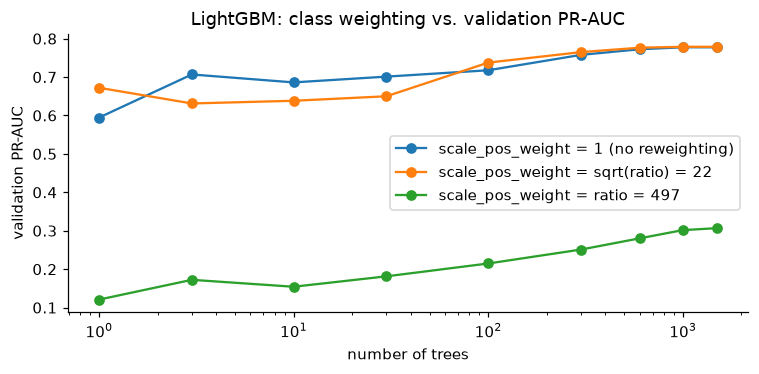

In [7]:
import warnings; warnings.filterwarnings("ignore", category=UserWarning)
import lightgbm as lgb
from sklearn.metrics import average_precision_score
from part_a_fraud.src.data import xy

Xtr, ytr = xy(train); Xva, yva = xy(val)
ratio = (ytr == 0).sum() / (ytr == 1).sum()
trees = [1, 3, 10, 30, 100, 300, 600, 1000, 1500]
fig, ax = plt.subplots(figsize=(7, 3.5))
for spw, label in [(1, "1 (no reweighting)"), (np.sqrt(ratio), f"sqrt(ratio) = {np.sqrt(ratio):.0f}"), (ratio, f"ratio = {ratio:.0f}")]:
    m = lgb.LGBMClassifier(n_estimators=max(trees), learning_rate=0.03, num_leaves=31, min_child_samples=50,
                           subsample=.8, subsample_freq=1, colsample_bytree=.8, scale_pos_weight=spw,
                           random_state=42, verbose=-1).fit(Xtr, ytr)
    aps = [average_precision_score(yva, m.predict_proba(Xva, num_iteration=k)[:, 1]) for k in trees]
    ax.plot(trees, aps, marker="o", label=f"scale_pos_weight = {label}")
    print(f"{label:>22}: best val PR-AUC {max(aps):.3f} at {trees[int(np.argmax(aps))]} trees, at 1500 trees {aps[-1]:.3f}")
ax.set(xscale="log", xlabel="number of trees", ylabel="validation PR-AUC", title="LightGBM: class weighting vs. validation PR-AUC")
ax.legend(); plt.tight_layout(); plt.show()

**Decision: `scale_pos_weight = 1`.** Full reweighting (~497×) is far worse in every version we ran: here it plateaus around 0.31 against ~0.78, and with `Time` included it collapsed outright. Weighting each of ~340 frauds ~500× lets a handful of rows dominate every split. No reweighting and √ratio are equally good on validation (difference well within the noise of 57 frauds). We keep **1** because unweighted scores stay closer to real probabilities, which the cost-based threshold in section 3 relies on. Imbalance is handled by the **metric and the threshold**, not by reweighting.

*Disclosure:* while debugging, an exploratory script also printed test PR-AUC for these settings. The decision above is justified by validation alone.

## 2.2 Results on the test set (95% bootstrap CIs)

In [8]:
from part_a_fraud.src.evaluate import run, paired_difference, plot_pr_curves, ALERT_BUDGET, TARGET_PRECISION, N_BOOT
from part_a_fraud.src.train import save

res = run(retrain=True)   # trains on train, early-stops/thresholds on val, evaluates on test
print(f"Test: {len(res['test']):,} rows, {int(res['test']['Class'].sum())} frauds | alert budget {ALERT_BUDGET:.1%} "
      f"= {round(len(res['test']) * ALERT_BUDGET)} alerts | LightGBM trees: {res['models']['lightgbm'].best_iteration_}")
print("Validation-chosen thresholds for precision >= 80%:", {k: f"{v:.4f}" for k, v in res["thresholds"].items() if np.isfinite(v)})
res["table"]

Test: 56,746 rows, 74 frauds | alert budget 0.2% = 113 alerts | LightGBM trees: 915
Validation-chosen thresholds for precision >= 80%: {'logreg': '1.0000', 'lightgbm': '0.0654'}


model,always_legit,lightgbm,logreg
metric,,,
PR-AUC,0.001,"0.802 [0.715, 0.883]","0.744 [0.638, 0.855]"
ROC-AUC,0.500,"0.978 [0.960, 0.992]","0.982 [0.966, 0.994]"
recall @0.2% alerts,0.000,"0.784 [0.696, 0.877]","0.797 [0.708, 0.887]"
precision @0.2% alerts,0.000,"0.513 [0.398, 0.655]","0.522 [0.398, 0.664]"
fraud amount caught @0.2% alerts,0.000,"0.691 [0.417, 0.948]","0.690 [0.417, 0.948]"
recall @val-thr (P>=80%),0.000,"0.757 [0.662, 0.853]","0.676 [0.573, 0.778]"
precision @val-thr (P>=80%),0.000,"0.875 [0.787, 0.949]","0.943 [0.877, 1.000]"
accuracy @0.5,0.9987,"0.9995 [0.9993, 0.9997]","0.9717 [0.9701, 0.9731]"


In [9]:
y_te = res["test"]["Class"]
d, lo, hi = paired_difference(y_te, res["test_scores"]["lightgbm"], res["test_scores"]["logreg"])
print(f"PR-AUC, LightGBM minus LogReg (paired bootstrap): {d:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")
s = res["test_scores"]
for n in ["logreg", "lightgbm"]:
    flagged = s[n] >= res["thresholds"][n]
    print(f"{n:>9} at its val threshold: {flagged.sum()} alerts, {int((flagged & (y_te == 1)).sum())} of {int(y_te.sum())} frauds caught")

PR-AUC, LightGBM minus LogReg (paired bootstrap): +0.058  95% CI [-0.010, +0.123]
   logreg at its val threshold: 53 alerts, 50 of 74 frauds caught
 lightgbm at its val threshold: 64 alerts, 56 of 74 frauds caught


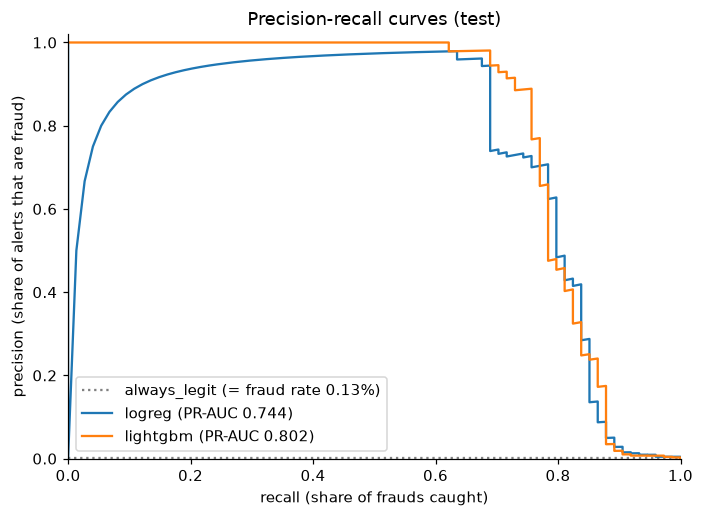

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.8))
plot_pr_curves(y_te, res["test_scores"], ax=ax)
plt.tight_layout(); plt.show()

**Reading the results**

- **Accuracy trap, confirmed:** `always_legit` has 99.87% accuracy, *higher* than Logistic Regression (97.2%), and catches nothing.
- **ROC-AUC doesn't separate the models** (0.978 vs. 0.982, LogReg even slightly ahead); **PR-AUC does** (LightGBM 0.80 vs. LogReg 0.74). ROC-AUC is dominated by the 56k legit rows; PR-AUC looks only at how clean the alerts are. This is why PR-AUC is primary.
- **But the gap is not conclusive:** the paired-bootstrap CI for the difference includes 0. With 74 test frauds we can say LightGBM is *probably* better, not *certainly*.
- **At the review-team budget (0.2% of transactions = 113 alerts)** the models are tied: both catch ~79–80% of frauds (58–59 of 74), and about half the alerts are real fraud. They catch ~69% of the fraud *money*, but that CI is very wide (≈0.42–0.95) because a few large frauds dominate the total.
- **At a threshold chosen on validation for ≥80% precision**, LightGBM keeps more recall (56 of 74 caught, 76%, with 88% precision) than LogReg (50 of 74, 68%, with 94% precision). The precision target carried over from validation to test, so the thresholds look reasonably stable.
- **LogReg's threshold sits at ≈1.0:** balanced class weights push its scores to the extremes, so they are not usable as probabilities. Calibration is examined in section 3 before any cost-based threshold.
- The dip at the very start of LogReg's curve is a single legit transaction ranked first on test; on validation its top 30 scores are all fraud. Not a systematic problem.

**Choice:** LightGBM as the primary model (better on the primary metric and at the operating point), with Logistic Regression kept as a transparent benchmark. The honest summary is "LightGBM is modestly better", not "LightGBM wins".

## 2.3 What drives the LightGBM score

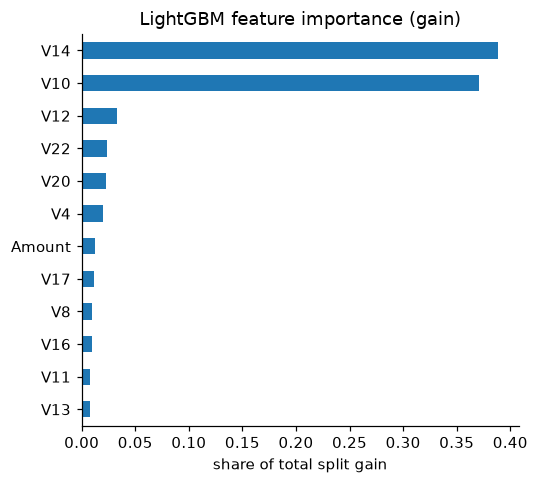

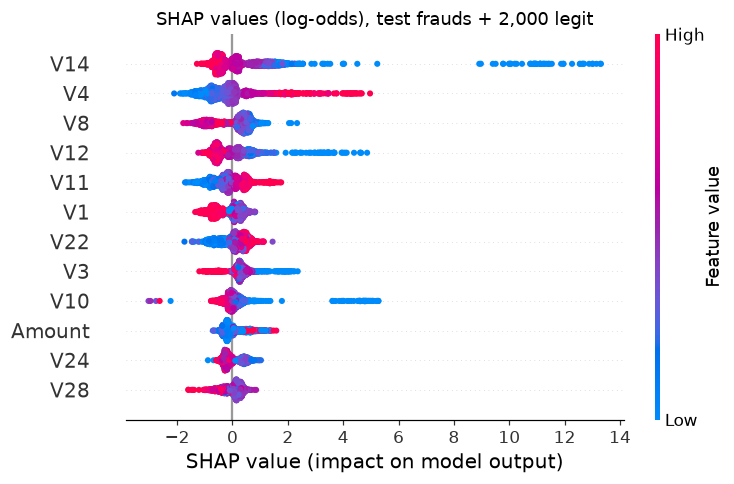

In [11]:
import shap
lgbm = res["models"]["lightgbm"]
from part_a_fraud.src.data import MODEL_FEATURES
X_te = res["test"][MODEL_FEATURES]
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=MODEL_FEATURES).sort_values()
imp = imp / imp.sum()

fig, ax = plt.subplots(figsize=(5, 4.5))
imp.tail(12).plot.barh(ax=ax, color="tab:blue"); ax.set(xlabel="share of total split gain", title="LightGBM feature importance (gain)")
plt.tight_layout(); plt.show()

# SHAP on all test frauds + a random sample of legit rows (direction and size of each feature's effect)
sample = pd.concat([X_te[y_te == 1], X_te[y_te == 0].sample(2000, random_state=0)])
sv = shap.TreeExplainer(lgbm).shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, sample, max_display=12, show=False, plot_size=(7, 4.5))
plt.title("SHAP values (log-odds), test frauds + 2,000 legit"); plt.tight_layout(); plt.show()

**Why `Time` was removed (found here).** The first version of the model included raw `Time`. Its SHAP plot showed `Time` as the feature with the *largest* effect, pushing **every** test transaction towards "legit" by about the same amount. `Time` only says *when in this 2-day file* a transaction happened. Test is always later than training, and both high-fraud nights are in training, so the model had learned "later = safer". That pattern belongs to this file, not to fraud, and in production `Time` grows beyond anything seen in training. Removing it: validation PR-AUC 0.765 → 0.778, test 0.809 → 0.802 (both changes within noise). It was dropped **on principle**, not for the score.

**Interpretation:** the model relies mostly on a few PCA components, consistent with the single-feature analysis in section 1. SHAP shows *direction*: low V14, V12 and V10 and high V4 push towards fraud, and a larger `Amount` pushes slightly towards fraud. Because these are anonymised PCA components, **we can't explain a decision to a customer or regulator in business terms** ("blocked because V14 was low" means nothing). This is the strongest argument for training a production model on raw, interpretable behavioural features (section 4).